> **Long run.** Same notebook with numbers of replicas, toy experiments and chain lengths close to those of the report.

# 05 · Bayesian analysis (1/3): posterior of $A_{\rm raw}$, Bayes factors and priors

**What this notebook does.** The *same* data and likelihood as the frequentist notebooks, analysed with Bayes' theorem:
a prior times the likelihood is the posterior of $A_{\rm raw}$, sampled with MCMC (`emcee`). Since the model is common,
any difference with notebook 01 comes from the inference.

| § | Content | Report section |
|---|---|---|
| 1 | Data, prior, likelihood, posterior | Bayesian analysis |
| 2 | MCMC, autocorrelation, trace plot from a dispersed start, Metropolis–Hastings by hand [EXTRA] | Bayesian analysis (add.: sampling) |
| 3 | Posterior, credible and HPD intervals | Posterior results |
| 4 | Bayes factors (evidence, Savage–Dickey [EXTRA]), dependence on the prior | Bayes factors (add.: priors) |

The Bayesian analysis continues in `06_Bayesian_systematics_and_checks` and `07_Bayesian_low_statistics`.

**Scale.** A guided tour of the method, not the production run: replicas, toy experiments and chains are fewer than in
the report, so numbers can differ slightly from it; next to every result the notebook prints the value of the report
(**report:**). The notebook is self-contained and saves its figures in `figures/` and its numbers in `results/`.
Parts beyond the techniques of the course are tagged **[EXTRA]**.

## 0 · Setup

In [1]:
import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot, emcee, corner
from scipy.special import ndtr
from scipy.stats import norm, chi2, crystalball, gaussian_kde
from iminuit import Minuit

import plot_style
plot_style.use()
C = plot_style.COLORS
T0 = time.time()
np.random.seed(42)

# figures and numerical results are saved next to the notebook
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
def save_fig(name):
    """Save the current figure in figures/ and show it."""
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

DATA_DIR = "data" if os.path.isdir("data") else "../../opendata-project/Data"
M_K = 493.677
LO, HI = 5100.0, 5600.0

## 1 · Data, prior, likelihood and posterior

### 1.1 Data
Same preselection and window as in notebook 01 (all three tracks kaon-like and not muons), here in compact form.
We keep the candidates with the weaker PID cut of the variants ($\texttt{ProbK}>0.4$, $\texttt{ProbPi}<0.6$) and
store the weakest PID value of each candidate, so that variants only re-apply tighter cuts.

In [2]:
tracks = (1, 2, 3)                          # the three final-state hadrons
branches = [f"H{i}_{v}" for i in tracks for v in ("PX", "PY", "PZ", "ProbK", "ProbPi", "isMuon", "Charge")]
frames = []
for pol in ("Down", "Up"):                  # one file per magnet polarity
    with uproot.open(f"{DATA_DIR}/B2HHH_Magnet{pol}.root") as f:
        t = f["DecayTree"].arrays(branches, library="pd")
    t["magnet"] = pol.lower()
    frames.append(t)
df = pd.concat(frames, ignore_index=True)

# loose preselection (looser than every variant of the systematic study): kaon-like and not muon on all three tracks
keep = np.ones(len(df), bool)
for i in tracks:
    keep &= ((df[f"H{i}_ProbK"] > 0.4) & (df[f"H{i}_ProbPi"] < 0.6) & ~df[f"H{i}_isMuon"].astype(bool)).to_numpy()
d = df[keep].reset_index(drop=True); del df

def invariant_mass(d, particles):
    """Invariant mass [MeV] of the listed tracks with the kaon-mass hypothesis: m^2 = E^2 - |p|^2."""
    E = sum(np.sqrt(d[f"H{i}_PX"]**2 + d[f"H{i}_PY"]**2 + d[f"H{i}_PZ"]**2 + M_K**2) for i in particles)
    px, py, pz = (sum(d[f"H{i}_{c}"] for i in particles) for c in ("PX", "PY", "PZ"))
    return np.sqrt(np.clip(E**2 - px**2 - py**2 - pz**2, 0, None))

d["m"], d["m12"], d["m13"] = invariant_mass(d, (1, 2, 3)), invariant_mass(d, (1, 2)), invariant_mass(d, (1, 3))
d["q"] = d.H1_Charge + d.H2_Charge + d.H3_Charge                      # charge of the B
d["min_probk"] = d[[f"H{i}_ProbK" for i in tracks]].min(axis=1)       # weakest kaon likelihood of the candidate
d["max_probpi"] = d[[f"H{i}_ProbPi" for i in tracks]].max(axis=1)     # largest pion likelihood of the candidate
d = d[np.abs(d.q) == 1]

def select(lo=LO, hi=HI, k=0.5, pi=0.5, s=None):
    """Candidates with mass in (lo, hi), min ProbK > k and max ProbPi < pi (nominal: 0.5, 0.5)."""
    s = d if s is None else s
    return s[(s.m > lo) & (s.m < hi) & (s.min_probk > k) & (s.max_probpi < pi)].reset_index(drop=True)

sample = select()                                                     # nominal sample
m_pos, m_neg = sample.m[sample.q > 0].to_numpy(), sample.m[sample.q < 0].to_numpy()
print(f"candidates in the window: {len(sample)} (report 19731);  B+: {len(m_pos)}, B-: {len(m_neg)}")

candidates in the window: 19731 (report 19731);  B+: 10292, B-: 9439


### 1.2 The model, written as log-prior, log-likelihood and log-posterior

The model is that of notebook 01: for each charge a Gaussian signal (mean $\mu$ and width $\sigma$ shared) and a
double-exponential background (own shape and yield), $N_s^\pm=\frac{N_s}{2}(1\mp A)$,
$N_b^\pm=\frac{N_b}{2}(1\mp A_b)$. Twelve parameters
$\theta=(N_s,N_b,A,A_b,\mu,\sigma,\lambda_1^\pm,\lambda_2^\pm,f_\pm)$.

* **Prior** $\pi(\theta)$: independent and **uniform** on the ranges below (constant in the allowed region, zero
  outside); $\lambda_1>\lambda_2$ removes the label-switching symmetry of the two exponentials. With flat priors the
  posterior is proportional to the likelihood inside the allowed region.
* **Likelihood**: the extended unbinned likelihood of notebook 01.
* **Posterior**: $\ln p(\theta|D)=\ln\mathcal L(D|\theta)+\ln\pi(\theta)$ + const. The evidence $p(D)$ is a constant
  that the MCMC does not need.

In [3]:
# the 12 parameters, in the order of the vector theta used by the sampler
names = ["N_s", "N_b", "A", "A_b", "mu", "sigma", "lam1_pos", "lam2_pos", "f_pos", "lam1_neg", "lam2_neg", "f_neg"]
N = len(sample)
# uniform prior = allowed range of each parameter (zero probability outside)
PRIOR = {"N_s": (0, 5 * N), "N_b": (0, 5 * N), "A": (-1, 1), "A_b": (-1, 1), "mu": (5260, 5310), "sigma": (3, 40),
         "lam1_pos": (1e-5, 0.1), "lam2_pos": (1e-5, 0.1), "f_pos": (0, 1),
         "lam1_neg": (1e-5, 0.1), "lam2_neg": (1e-5, 0.1), "f_neg": (0, 1)}

# building blocks of the model, as in notebook 01
def gauss_pdf(m, mu, sigma, lo=LO, hi=HI):
    """Gaussian normalised on [lo, hi]: written with ndtr (the normal cdf) because it is faster than scipy.stats."""
    z = (m - mu) / sigma
    return np.exp(-0.5 * z * z) / (sigma * np.sqrt(2 * np.pi)) / (ndtr((hi - mu) / sigma) - ndtr((lo - mu) / sigma))

def exp_pdf(m, lam, lo=LO, hi=HI):
    """Exponential exp(-lam (m - lo)) normalised on [lo, hi]."""
    return lam * np.exp(-lam * (m - lo)) / (1 - np.exp(-lam * (hi - lo)))

def bkg_pdf(m, lam1, lam2, f, lo=LO, hi=HI):
    """Background: weight f on the steep exponential (lam1 > lam2), 1 - f on the slow one."""
    return f * exp_pdf(m, lam1, lo, hi) + (1 - f) * exp_pdf(m, lam2, lo, hi)

def log_prior(theta):
    """ln of the prior: 0 inside the allowed region (uniform, an irrelevant constant), -inf outside."""
    v = dict(zip(names, theta))
    for k in names:
        if not PRIOR[k][0] < v[k] < PRIOR[k][1]:
            return -np.inf
    if v["lam1_pos"] <= v["lam2_pos"] or v["lam1_neg"] <= v["lam2_neg"]:      # ordering of the two exponentials
        return -np.inf                                                       # (removes the label-switching symmetry)
    return 0.0

def log_likelihood(theta, m_p, m_n):
    """ln of the extended unbinned likelihood of the B+ masses m_p and B- masses m_n."""
    v = dict(zip(names, theta))
    Ns_p, Ns_n = v["N_s"] * (1 - v["A"]) / 2, v["N_s"] * (1 + v["A"]) / 2          # signal yields per charge
    Nb_p, Nb_n = v["N_b"] * (1 - v["A_b"]) / 2, v["N_b"] * (1 + v["A_b"]) / 2      # background yields per charge
    dens_p = Ns_p * gauss_pdf(m_p, v["mu"], v["sigma"]) + Nb_p * bkg_pdf(m_p, v["lam1_pos"], v["lam2_pos"], v["f_pos"])
    dens_n = Ns_n * gauss_pdf(m_n, v["mu"], v["sigma"]) + Nb_n * bkg_pdf(m_n, v["lam1_neg"], v["lam2_neg"], v["f_neg"])
    return np.sum(np.log(dens_p)) + np.sum(np.log(dens_n)) - (v["N_s"] + v["N_b"])    # extended: -(N_s + N_b)

def log_posterior(theta, m_p=m_pos, m_n=m_neg):
    """ln posterior = ln prior + ln likelihood (up to a constant: the evidence)."""
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    ll = log_likelihood(theta, m_p, m_n)
    return lp + ll if np.isfinite(ll) else -np.inf

### 1.3 Starting point: the maximum of the posterior

With flat priors the maximum of the posterior (MAP) is the maximum-likelihood estimate: we find it with `Migrad`
and use it to start the walkers close to the bulk.

In [4]:
# rough starting values
theta0 = dict(N_s=0.78 * N, N_b=0.22 * N, A=-0.04, A_b=0.0, mu=5284.0, sigma=18.0,
              lam1_pos=0.03, lam2_pos=0.002, f_pos=0.15, lam1_neg=0.03, lam2_neg=0.002, f_neg=0.15)

def neg2logp(*theta):
    """-2 ln posterior, the function that Migrad minimises (a large number outside the prior)."""
    lp = log_posterior(np.array(theta))
    return -2 * lp if np.isfinite(lp) else 1e10

mmap = Minuit(neg2logp, *[theta0[k] for k in names], name=names)
for k in names:
    mmap.limits[k] = PRIOR[k]               # the prior ranges are the limits of the minimisation
mmap.migrad()
theta_map = np.array(mmap.values)           # maximum of the posterior (= maximum likelihood with flat priors)
print(f"MAP: A = {mmap.values['A']:+.4f},  N_s = {mmap.values['N_s']:.0f},  mu = {mmap.values['mu']:.2f},  "
      f"sigma = {mmap.values['sigma']:.2f}   (valid: {mmap.valid})")
# cost of one evaluation: sets the cost of the MCMC (walkers x steps evaluations)
t0 = time.time(); [log_posterior(theta_map) for _ in range(200)]
print(f"time per log-posterior call: {(time.time() - t0) / 200 * 1e3:.2f} ms")

MAP: A = -0.0441,  N_s = 15328,  mu = 5284.38,  sigma = 18.00   (valid: True)
time per log-posterior call: 0.43 ms


## 2 · Sampling the posterior with MCMC

`emcee` runs an *ensemble* of walkers (affine-invariant sampler of Goodman and Weare), which needs no tuning of the
proposal and works on correlated posteriors. We start 32 walkers in a small ball around the MAP, discard the first
steps as **burn-in** and keep the rest as samples of the posterior.

*Report:* 25 000 steps. Here 8 000 (the chain is then ~45 autocorrelation times long, close to the usual threshold of 50: enough for a demonstration; the diagnostics below quantify it).

In [5]:
NWALKERS, NSTEPS, BURN = 32, 25000, 5000
ndim = len(names)
p0 = theta_map + 1e-3 * np.abs(theta_map) * np.random.randn(NWALKERS, ndim)
for k in ("A", "A_b"):                                   # A and A_b are close to zero: use an absolute spread
    p0[:, names.index(k)] = theta_map[names.index(k)] + 1e-3 * np.random.randn(NWALKERS)

sampler = emcee.EnsembleSampler(NWALKERS, ndim, log_posterior)
t0 = time.time()
sampler.run_mcmc(p0, NSTEPS, progress=False)
print(f"MCMC: {NWALKERS} walkers x {NSTEPS} steps in {time.time() - t0:.0f} s")

chain = sampler.get_chain(discard=BURN, flat=True)             # (walkers * (steps - burn), 12) samples of the posterior
tau = sampler.get_autocorr_time(discard=BURN, quiet=True)
print(f"samples: {chain.shape[0]};  acceptance fraction: {sampler.acceptance_fraction.mean():.2f}   (report: 0.38)")
print(f"integrated autocorrelation time: {tau.min():.0f} - {tau.max():.0f} steps   (report: 147 - 183)")
print(f"chain length / tau = {(NSTEPS - BURN) / tau.max():.0f}   (rule of thumb: > 50;  report 113)")

MCMC: 32 walkers x 25000 steps in 360 s


samples: 640000;  acceptance fraction: 0.38   (report: 0.38)
integrated autocorrelation time: 146 - 175 steps   (report: 147 - 183)
chain length / tau = 114   (rule of thumb: > 50;  report 113)


**Reading the result.** An acceptance fraction of $0.3$–$0.4$ is typical of a healthy ensemble sampler. The integrated autocorrelation time $\tau$ is the number of steps after which samples are effectively independent; a chain longer than about $50\,\tau$ gives a reliable estimate of the posterior (the report uses a longer chain).

### 2.1 Convergence: trace plot from a dispersed start

A chain started near the maximum could hide a second mode. We start 32 walkers **uniformly over the whole prior
box** and check that they all end in the same place (the dotted line marks half of the chain).

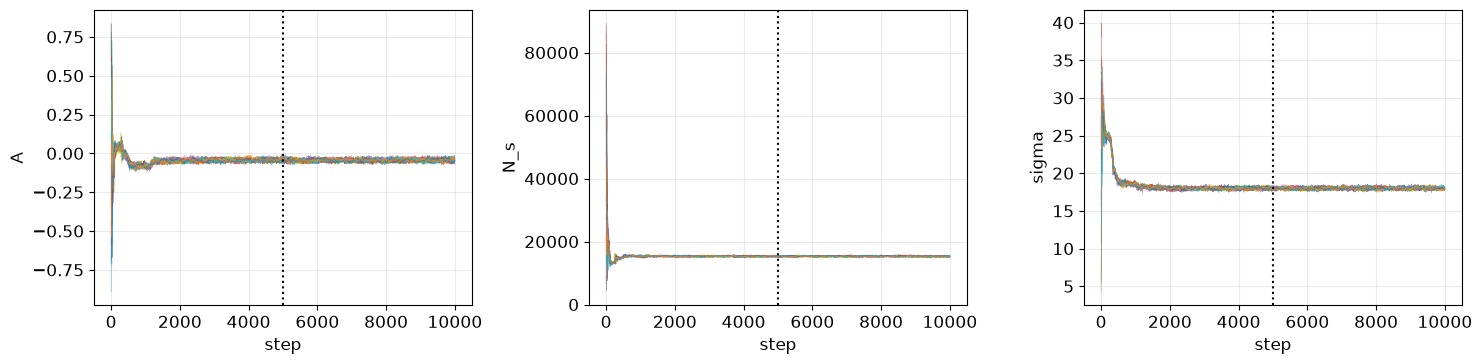

dispersed start: A = -0.0440 (report: -0.0446, -0.0442);  walkers in the bulk: 32/32


In [6]:
rng = np.random.default_rng(7)
lo_box = np.array([PRIOR[k][0] for k in names]); hi_box = np.array([PRIOR[k][1] for k in names])
# walkers uniformly distributed over the whole prior box (far from the posterior)
p_disp = lo_box + (hi_box - lo_box) * rng.uniform(0.02, 0.98, (NWALKERS, ndim))
for w in range(NWALKERS):                                 # every walker must start where the posterior is non-zero
    while not np.isfinite(log_posterior(p_disp[w])):
        p_disp[w] = lo_box + (hi_box - lo_box) * rng.uniform(0.02, 0.98, ndim)
N_DISP = 10000
samp_d = emcee.EnsembleSampler(NWALKERS, ndim, log_posterior)
samp_d.run_mcmc(p_disp, N_DISP, progress=False)
tr = samp_d.get_chain()                                   # shape (steps, walkers, parameters)

# one line per walker: they must all converge to the same value (dotted line: half of the chain)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, k in zip(ax, ("A", "N_s", "sigma")):
    a.plot(tr[:, :, names.index(k)], lw=0.4, alpha=0.6)
    a.axvline(N_DISP // 2, color="k", ls=":"); a.set(xlabel="step", ylabel=k)
plt.tight_layout(); save_fig("05_trace_dispersed_start")
A_disp = samp_d.get_chain(discard=N_DISP // 2, flat=True)[:, names.index("A")]
print(f"dispersed start: A = {np.median(A_disp):+.4f} (report: -0.0446, -0.0442);  "
      f"walkers in the bulk: {np.sum(samp_d.get_log_prob()[-1] > log_posterior(theta_map) - 20)}/{NWALKERS}")

### 2.2 An independent sampler: Metropolis–Hastings written by hand [EXTRA]

To see what `emcee` does and to check the implementation we write the simplest MCMC: from $\theta$ propose
$\theta'=\theta+\text{(Gaussian step)}$ and accept it with probability $\min(1,p(\theta')/p(\theta))$, so that the
chain satisfies detailed balance with the posterior as stationary distribution. The covariance of the step is that
of the `emcee` posterior scaled by $2.38^2/d$ (optimal for a Gaussian target).

In [7]:
def metropolis_hastings(logp, x0, cov, n_steps):
    """Random-walk Metropolis-Hastings with a Gaussian proposal of covariance cov * 2.38^2 / d."""
    d_ = len(x0)
    L = np.linalg.cholesky(cov * 2.38**2 / d_)            # to draw correlated Gaussian steps
    x, lp = x0.copy(), logp(x0)                           # current point and its log-posterior
    out, n_acc = np.empty((n_steps, d_)), 0
    for i in range(n_steps):
        y = x + L @ np.random.randn(d_)                   # proposal: current point + Gaussian step
        lp_y = logp(y)
        if np.log(np.random.uniform()) < lp_y - lp:       # accept with probability min(1, p(y) / p(x))
            x, lp, n_acc = y, lp_y, n_acc + 1
        out[i] = x                                        # a rejected step repeats the current point
    return out, n_acc / n_steps

t0 = time.time()
mh, acc = metropolis_hastings(log_posterior, theta_map, np.cov(chain.T), 120000)
mh = mh[20000:]                                            # burn-in
A_mh = mh[:, names.index("A")]
print(f"Metropolis-Hastings: {time.time() - t0:.0f} s, acceptance {acc:.2f}")
print(f"  A = {np.median(A_mh):+.4f} +- {A_mh.std():.4f}      emcee: A = {np.median(chain[:, 2]):+.4f} +- {chain[:, 2].std():.4f}")

Metropolis-Hastings: 42 s, acceptance 0.24
  A = -0.0440 +- 0.0084      emcee: A = -0.0442 +- 0.0085


## 3 · Posterior of $A_{\rm raw}$ and credible intervals

The marginal posterior of $A$ is the histogram of the $A$ component of the chain (the other 11 parameters are
*marginalised*: this is what the Bayesian analysis does where the frequentist one *profiles*). We quote the median
and the equal-tailed 68 %/95 % **credible intervals** (percentiles), and the **highest posterior density** (HPD)
interval, the shortest interval with 68 % probability.

A_raw = -0.0442   68% CI [-0.0527, -0.0357]   95% CI [-0.0608, -0.0276]   sd 0.0085
  report: -0.0443, [-0.0528, -0.0358], [-0.0608, -0.0276], sd 0.0085
HPD 68%: [-0.0526, -0.0356]   (report: [-0.0525, -0.0355])
A_b = -0.040 +- 0.017   (report: -0.040 +- 0.018);  N_s = 15328 +- 132  (report: 15328 +- 133)
equal-tailed against HPD 68% intervals (the skewness tells when they differ):
  A         median   -0.0442  equal-tailed [ -0.0527,  -0.0357]  HPD [ -0.0526,  -0.0356]  skew -0.00


  A_b       median   -0.0402  equal-tailed [ -0.0576,  -0.0226]  HPD [ -0.0570,  -0.0221]  skew +0.00


  f_pos     median    0.1129  equal-tailed [  0.0879,   0.1437]  HPD [  0.0826,   0.1370]  skew +0.85
  f_neg     median    0.2104  equal-tailed [  0.1744,   0.2506]  HPD [  0.1708,   0.2465]  skew +0.35
  lam1_pos  median    0.0353  equal-tailed [  0.0281,   0.0437]  HPD [  0.0270,   0.0424]  skew +0.56
report: the two intervals coincide for A and A_b; for skewed parameters (f_+: skew +0.90) the HPD is shifted to the mode


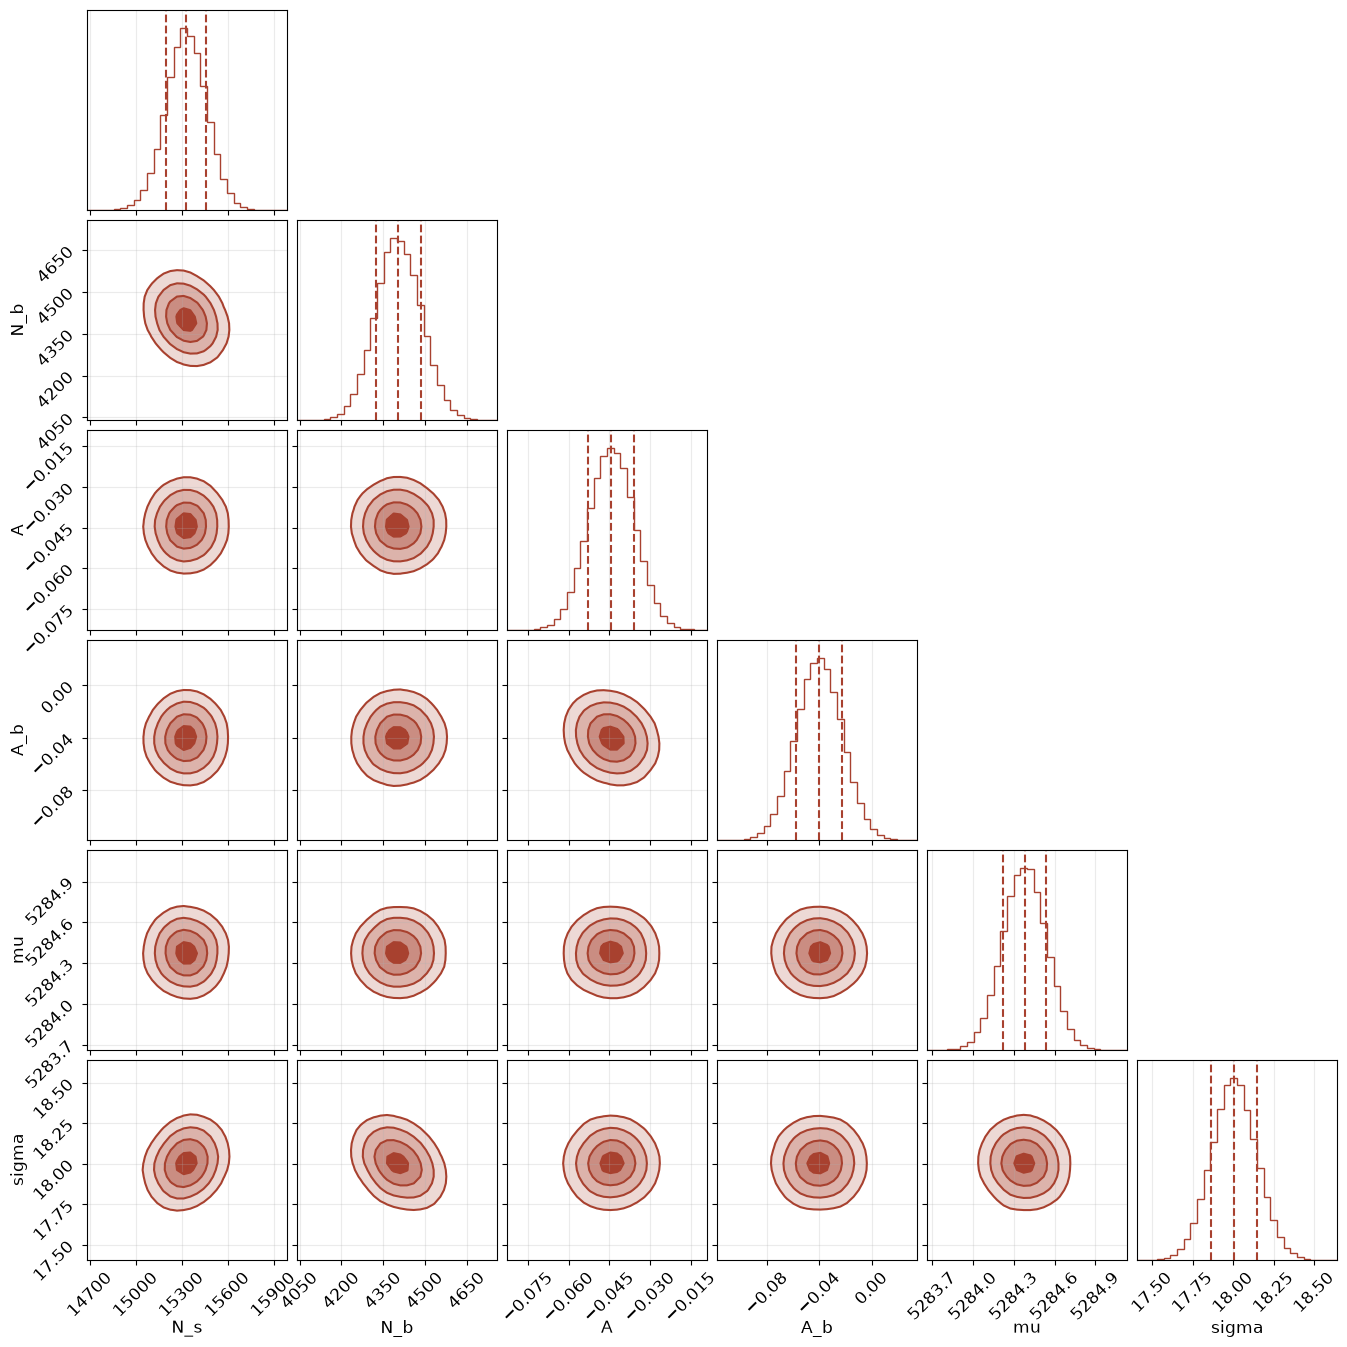

In [8]:
A_s, Ab_s = chain[:, names.index("A")], chain[:, names.index("A_b")]    # marginal posteriors = columns of the chain

def hpd(x, p=0.6827):
    """Highest posterior density interval: the shortest interval that contains a fraction p of the samples."""
    s = np.sort(x); k = int(np.ceil(p * len(s)))
    j = np.argmin(s[k:] - s[:len(s) - k])                 # start of the shortest window containing k samples
    return s[j], s[j + k]

# equal-tailed credible intervals: percentiles of the chain
q16, q50, q84 = np.percentile(A_s, [15.865, 50, 84.135])
q025, q975 = np.percentile(A_s, [2.5, 97.5])
print(f"A_raw = {q50:+.4f}   68% CI [{q16:+.4f}, {q84:+.4f}]   95% CI [{q025:+.4f}, {q975:+.4f}]   sd {A_s.std():.4f}")
print("  report: -0.0443, [-0.0528, -0.0358], [-0.0608, -0.0276], sd 0.0085")
print(f"HPD 68%: [{hpd(A_s)[0]:+.4f}, {hpd(A_s)[1]:+.4f}]   (report: [-0.0525, -0.0355])")
print(f"A_b = {np.median(Ab_s):+.3f} +- {Ab_s.std():.3f}   (report: -0.040 +- 0.018);  "
      f"N_s = {np.median(chain[:, 0]):.0f} +- {chain[:, 0].std():.0f}  (report: 15328 +- 133)")

# equal-tailed against HPD for a few parameters: they coincide for symmetric posteriors, differ for skewed ones
from scipy.stats import skew
print("equal-tailed against HPD 68% intervals (the skewness tells when they differ):")
for k in ("A", "A_b", "f_pos", "f_neg", "lam1_pos"):
    x = chain[:, names.index(k)]
    e16, e84 = np.percentile(x, [15.865, 84.135]); h = hpd(x)
    print(f"  {k:9s} median {np.median(x):9.4f}  equal-tailed [{e16:8.4f}, {e84:8.4f}]  HPD [{h[0]:8.4f}, {h[1]:8.4f}]  skew {skew(x):+.2f}")
print("report: the two intervals coincide for A and A_b; for skewed parameters (f_+: skew +0.90) the HPD is shifted to the mode")

# corner plot: marginal posteriors (diagonal) and pairwise correlations of the six physical parameters
main = ["N_s", "N_b", "A", "A_b", "mu", "sigma"]
fig = corner.corner(chain[:, [names.index(k) for k in main]], labels=main, quantiles=[0.16, 0.5, 0.84],
                    color=C["bayes"], plot_datapoints=False, fill_contours=True, bins=30, smooth=1.0)
save_fig("05_corner")

**Reading the result.** The marginal posterior of $A$ is Gaussian, centred at about $-0.044$ with $\sigma\approx0.0085$, the same numbers as the frequentist fit. With a flat prior the posterior is proportional to the likelihood, so the *values* coincide while the *meaning* differs: a probability statement on $A$ given the data and the prior.

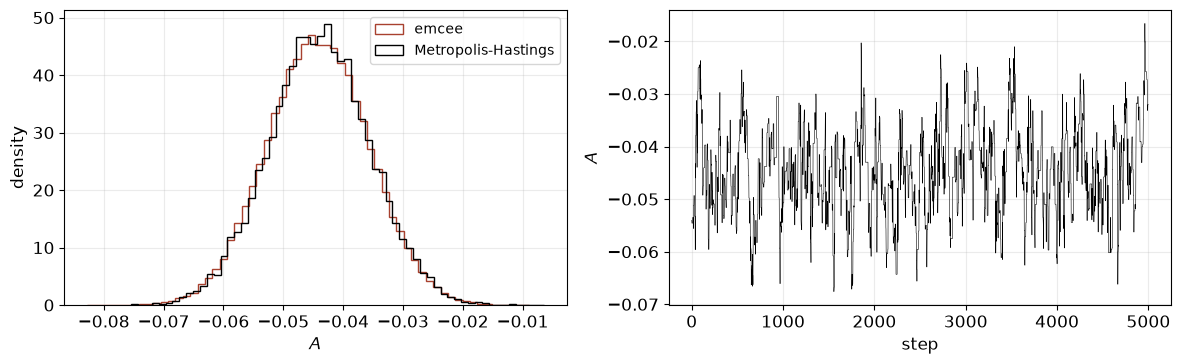

In [9]:
# the two samplers on the same posterior of A, and the Metropolis-Hastings trace
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(A_s, bins=60, density=True, histtype="step", color=C["bayes"], label="emcee")
ax[0].hist(A_mh, bins=60, density=True, histtype="step", color="k", label="Metropolis-Hastings")
ax[0].set(xlabel="$A$", ylabel="density"); ax[0].legend()
ax[1].plot(A_mh[:5000], lw=0.4, color="k"); ax[1].set(xlabel="step", ylabel="$A$")
plt.tight_layout(); save_fig("05_two_samplers")

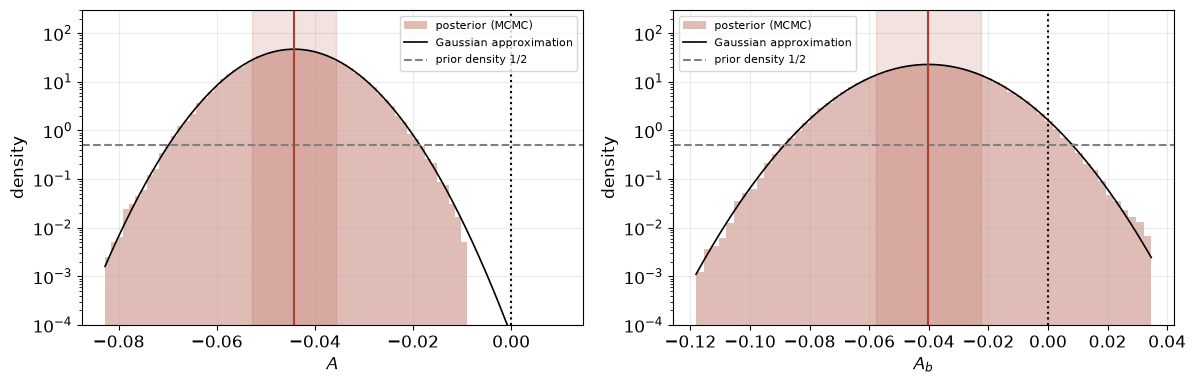

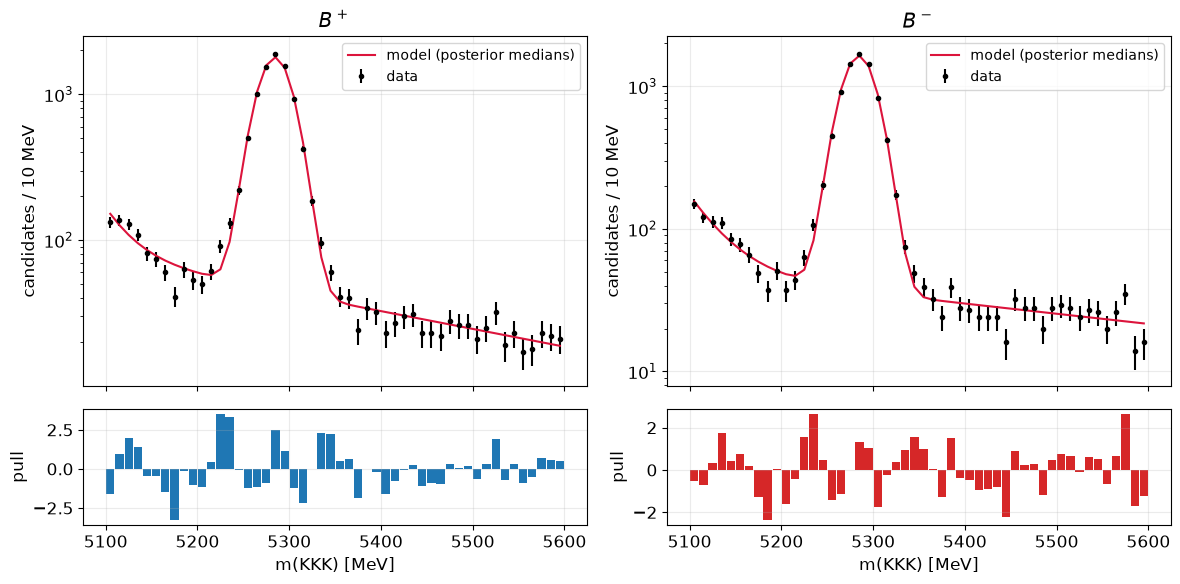

In [10]:
# --- summaries of all the parameters, saved: median, credible and HPD intervals, skewness, autocorrelation time
rows_p = []
for k, name in enumerate(names):
    x = chain[:, k]
    e16, e84 = np.percentile(x, [15.865, 84.135]); e025, e975 = np.percentile(x, [2.5, 97.5]); h = hpd(x)
    rows_p.append(dict(parameter=name, median=np.median(x), sd=x.std(), ci68_lo=e16, ci68_hi=e84, ci95_lo=e025, ci95_hi=e975,
                       hpd68_lo=h[0], hpd68_hi=h[1], skewness=skew(x), tau=tau[k]))
pd.DataFrame(rows_p).to_csv("results/05_posterior_summary.csv", index=False)

# --- posterior of A with its intervals, and of A_b, against the prior (Savage-Dickey densities at zero)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (par, x, lab) in zip(ax, (("A", A_s, "$A$"), ("A_b", Ab_s, "$A_b$"))):
    a.hist(x, bins=60, density=True, color=C["bayes"], alpha=0.35, label="posterior (MCMC)")
    xs = np.linspace(min(x.min(), -0.01), max(x.max(), 0.01), 400)
    a.plot(xs, norm.pdf(xs, x.mean(), x.std()), color="k", lw=1.2, label="Gaussian approximation")
    a.axhline(0.5, color="gray", ls="--", label="prior density $1/2$")
    a.axvline(np.median(x), color=C["bayes"]); a.axvspan(*np.percentile(x, [15.865, 84.135]), color=C["bayes"], alpha=0.15)
    a.axvline(0, color="k", ls=":"); a.set(xlabel=lab, ylabel="density", yscale="log", ylim=(1e-4, 300)); a.legend(fontsize=8)
plt.tight_layout(); save_fig("05_posterior_A_Ab")

# --- the nominal model at the posterior medians against the data (as in the frequentist notebook)
v_med = dict(zip(names, np.median(chain, axis=0)))
edges_f = np.arange(LO, HI + 1e-9, 10.0); cen_f = 0.5 * (edges_f[1:] + edges_f[:-1])
sub_f = (np.arange(5) + 0.5) / 5
pts_f = edges_f[:-1, None] + sub_f[None, :] * 10.0
fig, ax = plt.subplots(2, 2, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
tab_fit = {"m_center": cen_f}
for col_, (side, sign, mm, lab, c) in enumerate((("pos", -1, m_pos, "$B^+$", C["pos"]), ("neg", +1, m_neg, "$B^-$", C["neg"]))):
    nu = ((v_med["N_s"] * (1 + sign * v_med["A"]) / 2) * gauss_pdf(pts_f, v_med["mu"], v_med["sigma"])
          + (v_med["N_b"] * (1 + sign * v_med["A_b"]) / 2) * bkg_pdf(pts_f, v_med[f"lam1_{side}"], v_med[f"lam2_{side}"], v_med[f"f_{side}"])
          ).mean(axis=1) * 10.0
    obs = np.histogram(mm, edges_f)[0]
    tab_fit[f"obs_{side}"], tab_fit[f"model_{side}"] = obs, nu
    ax[0, col_].errorbar(cen_f, obs, np.sqrt(obs), fmt="o", ms=3, color="k", label="data")
    ax[0, col_].plot(cen_f, nu, color=C["model"], label="model (posterior medians)")
    ax[0, col_].set(yscale="log", ylabel="candidates / 10 MeV", title=lab); ax[0, col_].legend()
    ax[1, col_].bar(cen_f, (obs - nu) / np.sqrt(nu), width=9, color=c); ax[1, col_].set(xlabel="m(KKK) [MeV]", ylabel="pull")
plt.tight_layout(); save_fig("05_mass_fit_pulls")
pd.DataFrame(tab_fit).to_csv("results/05_mass_fit_bins.csv", index=False)

Two remarks. (i) $A$ is almost uncorrelated with the other parameters, which is why marginalising (Bayesian) and
profiling (frequentist) the nuisance parameters give the same answer. (ii) The largest correlation is with $A_b$:
if the background were symmetric ($A_b=0$) $A$ would move accordingly, which is one of the systematic variants.
[EXTRA] The *conditional* posterior of $A$ at $A_b=0$ for a Gaussian posterior has mean
$\bar A+\rho\,\sigma_A/\sigma_{A_b}\,(0-\bar A_b)$:

In [11]:
cov = np.cov(A_s, Ab_s)
rho = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
A_cond = A_s.mean() + cov[0, 1] / cov[1, 1] * (0 - Ab_s.mean())
print(f"corr(A, A_b) = {rho:+.2f} (report: -0.17);  A given A_b = 0: {A_cond:+.4f}   (report: -0.0475; fit with A_b = 0: -0.0471)")

corr(A, A_b) = -0.17 (report: -0.17);  A given A_b = 0: -0.0476   (report: -0.0475; fit with A_b = 0: -0.0471)


## 4 · Bayes factors and dependence on the prior

The Bayes factor compares two hypotheses through their **evidences**,
$BF_{10}=P(D|H_1)/P(D|H_0)$, with $H_0:A=0$ and $H_1:A$ free with a uniform prior on $(-1,1)$.

**Evidence by direct integration** (the method of the course). $P(D|H_1)=\int\mathcal L\,\pi\,dA$; as a
simplification we fix the nuisance parameters at the MAP (a grid in $A$ only), so this is a *conditional* Bayes factor.

**Savage–Dickey ratio** [EXTRA]. For nested hypotheses and shared priors on the nuisance parameters,
$BF_{01}=p(A=0|D)/\pi(A=0)$: no integral over the 12 parameters. $A=0$ is $5\sigma$ from the median, where the
chain has no samples, so $p(A=0|D)$ is taken from the Gaussian approximation of the posterior.

In [12]:
# (a) evidence by direct integration over A, nuisance parameters fixed at the MAP
A_grid = np.linspace(-0.2, 0.2, 801)
ll = np.array([log_likelihood(np.where(np.arange(ndim) == 2, a, theta_map), m_pos, m_neg) for a in A_grid])
L = np.exp(ll - ll.max())
Z1 = np.trapezoid(L * 0.5, A_grid)                       # prior density 1/2 on (-1, 1)
L0 = np.exp(log_likelihood(np.where(np.arange(ndim) == 2, 0.0, theta_map), m_pos, m_neg) - ll.max())
print(f"evidence by integration (grid):  BF_01 = {L0 / Z1:.2e}")

# (b) Savage-Dickey with the Gaussian approximation of the marginal posterior
def savage_dickey(x, prior_density):
    return norm.pdf(0.0, x.mean(), x.std()) / prior_density

bf_A, bf_Ab = savage_dickey(A_s, 0.5), savage_dickey(Ab_s, 0.5)
print(f"Savage-Dickey, A = 0:   BF_01 = {bf_A:.2e}, BF_10 = {1 / bf_A:.1e}     (report: 1.1e-4, 9e3; decisive on Jeffreys' scale)")
print(f"Savage-Dickey, A_b = 0: BF_01 = {bf_Ab:.2f}, BF_10 = {1 / bf_Ab:.2f}     (report: BF_01 = 3.5)")

evidence by integration (grid):  BF_01 = 7.02e-05
Savage-Dickey, A = 0:   BF_01 = 1.24e-04, BF_10 = 8.1e+03     (report: 1.1e-4, 9e3; decisive on Jeffreys' scale)
Savage-Dickey, A_b = 0: BF_01 = 3.28, BF_10 = 0.30     (report: BF_01 = 3.5)


**Reading the result.** $BF_{01}\sim10^{-4}$ (equivalently $BF_{10}\sim10^{4}$): decisive evidence against $A=0$ on Jeffreys' scale. Unlike the credible interval, the Bayes factor depends on the prior width (next cells): that is the price of comparing models through their evidences.

**The Ockham factor.** $A_b$ is $2.3\sigma$ from zero and yet $BF_{01}(A_b=0)>1$: the likelihood gain does not
compensate for spreading the prior over $(-1,1)$. The Bayes factor *depends on the prior width* $W$
($BF_{01}=p(0|D)\cdot2W$ for a uniform prior on $(-W,W)$), whereas the posterior of $A$ does not.

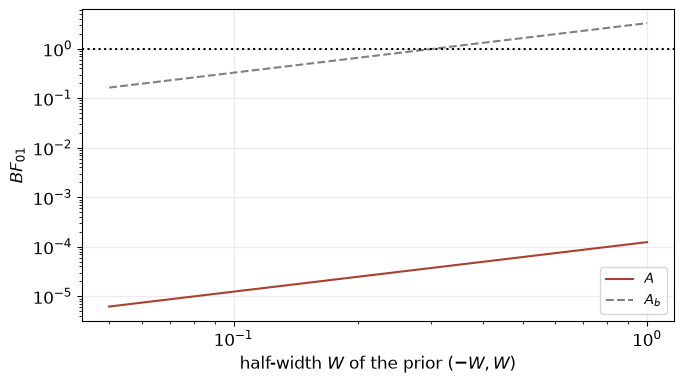

BF_01(A = 0) with A in (-0.3, 0.3): 3.7e-05   (drops by a factor 3.3; report: factor 3.3, the conclusion is unchanged)


In [13]:
# Savage-Dickey Bayes factor as a function of the half-width W of the uniform prior on (-W, W): BF_01 = p(0|D) * 2W
W = np.geomspace(0.05, 1.0, 40)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(W, norm.pdf(0, A_s.mean(), A_s.std()) * 2 * W, color=C["bayes"], label="$A$")
ax.plot(W, norm.pdf(0, Ab_s.mean(), Ab_s.std()) * 2 * W, color="gray", ls="--", label="$A_b$")
ax.axhline(1, color="k", ls=":"); ax.set(xscale="log", yscale="log", xlabel="half-width $W$ of the prior $(-W,W)$", ylabel="$BF_{01}$")
ax.legend(); plt.tight_layout(); save_fig("05_bayes_factor_prior_width")
bf_narrow = norm.pdf(0, A_s.mean(), A_s.std()) * 0.6      # W = 0.3
print(f"BF_01(A = 0) with A in (-0.3, 0.3): {bf_narrow:.1e}   "
      f"(drops by a factor {bf_A / bf_narrow:.1f}; report: factor 3.3, the conclusion is unchanged)")

**Dependence of the posterior on the prior** [EXTRA]. We can obtain the posterior under *another* prior without a new
MCMC by **reweighting** the chain with $\pi'(\theta)/\pi(\theta)$. For example, log-uniform priors on the yields or on
the slopes (scale-invariant), or a flat prior on $(N_s^+,N_s^-)$ instead of $(N_s,A)$ (Jacobian $N_s$). The effective
sample size $1/\sum w^2$ tells how reliable each reweighting is.

In [14]:
# importance weights w = new prior / old prior: the weighted chain is the posterior under the new prior
col = lambda k: chain[:, names.index(k)]
lam = np.vstack([col(k) for k in ("lam1_pos", "lam2_pos", "lam1_neg", "lam2_neg")])
alt_priors = {"nominal (uniform)": np.ones(len(chain)),
              "log-uniform N_s, N_b": 1 / (col("N_s") * col("N_b")),
              "log-uniform slopes": 1 / lam.prod(axis=0),
              "uniform in 1/lambda": lam.prod(axis=0)**-2.0,
              "flat in (N_s+, N_s-)": col("N_s"),                          # Jacobian of (N_s, A) -> (N_s+, N_s-)
              "flat in (N_s+-) and (N_b+-)": col("N_s") * col("N_b")}

def wquantile(x, w, q):
    """Quantile q of the samples x with weights w."""
    o = np.argsort(x); c = np.cumsum(w[o]) / w.sum()
    return x[o][np.searchsorted(c, q)]

print(f"{'prior':26s} {'median A':>9s}  {'68% interval':>20s}   ESS")
prior_rows = []
for lab, w in alt_priors.items():
    w = w / w.sum()
    prior_rows.append(dict(prior=lab, median=wquantile(A_s, w, 0.5), lo68=wquantile(A_s, w, 0.1587), hi68=wquantile(A_s, w, 0.8413), ess=1 / np.sum(w**2)))
    # ESS = effective sample size 1 / sum(w^2): how many independent samples the reweighted chain is worth
    print(f"{lab:26s} {wquantile(A_s, w, 0.5):+9.4f}  [{wquantile(A_s, w, 0.1587):+.4f}, {wquantile(A_s, w, 0.8413):+.4f}]  {1 / np.sum(w**2):7.0f}")
pd.DataFrame(prior_rows).to_csv("results/05_prior_reweighting.csv", index=False)
print("report: all medians -0.0440 ... -0.0444, intervals unchanged to 0.0002")

prior                       median A          68% interval   ESS


nominal (uniform)            -0.0442  [-0.0527, -0.0357]   640000


log-uniform N_s, N_b         -0.0442  [-0.0527, -0.0357]   639780


log-uniform slopes           -0.0439  [-0.0524, -0.0355]   241831


uniform in 1/lambda          -0.0445  [-0.0549, -0.0363]      305


flat in (N_s+, N_s-)         -0.0442  [-0.0527, -0.0357]   639953


flat in (N_s+-) and (N_b+-)   -0.0442  [-0.0527, -0.0357]   639780
report: all medians -0.0440 ... -0.0444, intervals unchanged to 0.0002


## Results saved

In [15]:
summary = dict(
    posterior=dict(A_median=float(np.median(A_s)), ci68=[float(q16), float(q84)], ci95=[float(q025), float(q975)],
                   sd=float(A_s.std()), hpd68=[float(x) for x in hpd(A_s)], A_b=float(np.median(Ab_s)), A_b_sd=float(Ab_s.std())),
    sampling=dict(n_walkers=NWALKERS, n_steps=NSTEPS, burn=BURN, acceptance=float(sampler.acceptance_fraction.mean()),
                  tau_max=float(tau.max())),
    bayes_factor=dict(BF01_A=float(bf_A), BF01_Ab=float(bf_Ab), BF01_A_by_integration=float(L0 / Z1)))
json.dump(summary, open("results/05_summary.json", "w"), indent=1)
np.save("results/05_posterior_samples.npy", chain[::25])
print("saved results/05_summary.json and the posterior sample; figures in figures/")

saved results/05_summary.json and the posterior sample; figures in figures/


## Summary
* With uniform priors the posterior of $A_{\rm raw}$ is Gaussian, centred where the maximum likelihood is, with the
  same width as the frequentist fit; the chain is long compared with its autocorrelation time and independent of the
  starting point and of the sampler.
* $A$ is almost uncorrelated with the other parameters, which is why marginalising and profiling agree.
* The **Bayes factor** of $A=0$ is decisive but scales with the prior width (Ockham factor), whereas the posterior of
  $A$ and its credible interval do not depend on the prior.

In [16]:
print(f"Running time of this notebook: {(time.time() - T0) / 60:.1f} min")

Running time of this notebook: 8.8 min
